--- Running CS-MPPT under Standard Test Conditions (1000 W/m^2) ---

FINAL MPPT RESULTS
Optimal Duty Cycle (D*) : 0.7783
Tracked Maximum Power   : 262.59 W


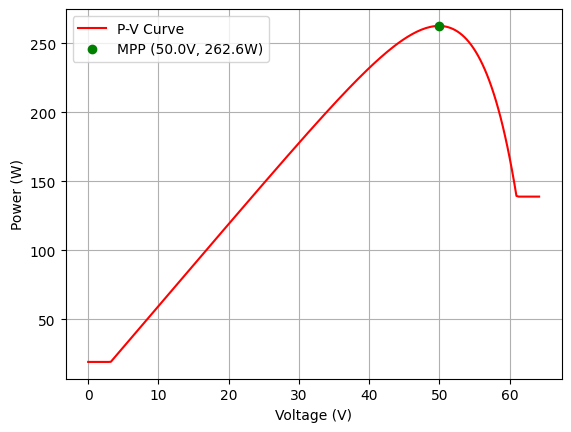

In [1]:
import numpy as np
import math  # Standard math module for gamma function
import matplotlib.pyplot as plt

class PVSystem:
    """
    Mathematical model of a PV module (Single-Diode Model approximation)
    """
    def __init__(self, Voc=64.2, Isc=5.96, Vmpp=54.7, Impp=5.49):
        self.Voc = Voc      # Open-circuit voltage
        self.Isc = Isc      # Short-circuit current
        self.Vmpp = Vmpp    # Voltage at MPP
        self.Impp = Impp    # Current at MPP
        self.Pmpp = Vmpp * Impp  # Peak Power (~300.30 W)

    def evaluate_power(self, duty_cycle, G=1000, T=25):
        """
        Evaluates PV power output based on duty cycle input D (0 <= D <= 1).
        Maps duty cycle to terminal voltage V_pv.
        """
        # Clamp duty cycle to valid operating range [0.05, 0.95]
        D = np.clip(duty_cycle, 0.05, 0.95)

        # Equivalent operating voltage based on Duty Cycle mapping
        V_pv = D * self.Voc

        # P-V Curve approximation using diode characteristics
        b = 0.15  # Adjusted shape factor for Voc = 64.2V
        if V_pv >= self.Voc:
            I_pv = 0.0
        else:
            I_pv = self.Isc * (1.0 - np.exp(b * (V_pv - self.Voc)))
            I_pv = max(0.0, I_pv)

        # Scale current with irradiance G (W/m^2)
        I_pv = I_pv * (G / 1000.0)

        power = V_pv * I_pv
        return float(power)


class CuckooSearchMPPT:
    """
    Cuckoo Search Algorithm for PV Maximum Power Point Tracking
    """
    def __init__(self, pv_system, num_nests=10, max_iter=30, pa=0.25, beta=1.5):
        self.pv = pv_system
        self.n = num_nests       # Number of host nests (candidate duty cycles)
        self.max_iter = max_iter # Maximum generations
        self.pa = pa             # Discovery probability of alien eggs
        self.beta = beta         # Lévy flight scaling parameter

        # Bounds for Duty Cycle (D)
        self.lb = 0.05
        self.ub = 0.95

    def _levy_flight(self, size):
        """
        Generates step sizes using Mantegna's algorithm for Lévy flights
        """
        sigma_u = (
            (math.gamma(1 + self.beta) * np.sin(np.pi * self.beta / 2)) /
            (math.gamma((1 + self.beta) / 2) * self.beta * (2 ** ((self.beta - 1) / 2)))
        ) ** (1 / self.beta)

        u = np.random.normal(0, sigma_u, size)
        v = np.random.normal(0, 1.0, size)
        step = u / (np.abs(v) ** (1 / self.beta))
        return step

    def track_mpp(self, G=1000, T=25):
        """
        Executes CS-MPPT optimization loop for given irradiance (G) and temperature (T)
        """
        # 1. Initialize host nests (random duty cycles in range [lb, ub])
        nests = np.random.uniform(self.lb, self.ub, self.n)
        fitness = np.array([self.pv.evaluate_power(d, G, T) for d in nests])

        # Track global best nest
        best_idx = np.argmax(fitness)
        best_nest = nests[best_idx]
        best_power = fitness[best_idx]

        for it in range(1, self.max_iter + 1):
            # 2. Generate new solutions via Lévy Flights
            step_size = 0.01 * self._levy_flight(self.n)
            new_nests = nests + step_size * (nests - best_nest)
            new_nests = np.clip(new_nests, self.lb, self.ub)

            # Evaluate fitness of new cuckoos
            for i in range(self.n):
                new_fit = self.pv.evaluate_power(new_nests[i], G, T)
                # Greedy replacement if new solution is better
                if new_fit > fitness[i]:
                    nests[i] = new_nests[i]
                    fitness[i] = new_fit

            # 3. Discovery and Nest Abandonment (fraction pa of worst nests)
            random_draw = np.random.rand(self.n)
            abandon_mask = random_draw < self.pa

            # Replace abandoned nests with new random walks
            random_steps = np.random.rand(self.n) * (nests[np.random.permutation(self.n)] -
                                                     nests[np.random.permutation(self.n)])
            nests[abandon_mask] = nests[abandon_mask] + random_steps[abandon_mask]
            nests = np.clip(nests, self.lb, self.ub)

            # Re-evaluate fitness after abandonment
            for i in range(self.n):
                fitness[i] = self.pv.evaluate_power(nests[i], G, T)

            # 4. Update Global Best
            current_best_idx = np.argmax(fitness)
            if fitness[current_best_idx] > best_power:
                best_power = fitness[current_best_idx]
                best_nest = nests[current_best_idx]

            # if it == 1 or it % 10 == 0 or it == self.max_iter:
            #     print(f"Iter {it:02d} | Best Duty Cycle (D): {best_nest:.4f} | Max Power: {best_power:.2f} W")

        return best_nest, best_power


# ==========================================
# Execution Example
# ==========================================
if __name__ == "__main__":
    pv = PVSystem()
    mppt_solver = CuckooSearchMPPT(pv_system=pv, num_nests=10, max_iter=30, pa=0.25)

    print("--- Running CS-MPPT under Standard Test Conditions (1000 W/m^2) ---")
    optimal_D, max_P = mppt_solver.track_mpp(G=1000, T=25)

    print("\n==========================================")
    print("FINAL MPPT RESULTS")
    print("==========================================")
    print(f"Optimal Duty Cycle (D*) : {optimal_D:.4f}")
    print(f"Tracked Maximum Power   : {max_P:.2f} W")

    # --- QUICK GRAPH CODE PASTED AT THE END ---
    v = np.linspace(0, pv.Voc, 200)
    p = [pv.evaluate_power(v_i / pv.Voc) for v_i in v]

    plt.plot(v, p, 'r-', label='P-V Curve')
    plt.plot(optimal_D * pv.Voc, max_P, 'go', label=f'MPP ({optimal_D*pv.Voc:.1f}V, {max_P:.1f}W)')
    plt.xlabel('Voltage (V)'); plt.ylabel('Power (W)'); plt.legend(); plt.grid(True); plt.show()